# 커스텀 예산 미들웨어

**이 노트북에서 할 일**

1. 모델 응답에 붙은 토큰 사용량을 읽습니다.
2. 예산 검사 없이 질문 두 개를 보내 둘 다 모델이 답하는 것을 확인합니다(Before).
3. 토큰 예산 미들웨어를 직접 만들어, 예산을 다 쓰면 모델을 부르지 않게 합니다(After).

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 6번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

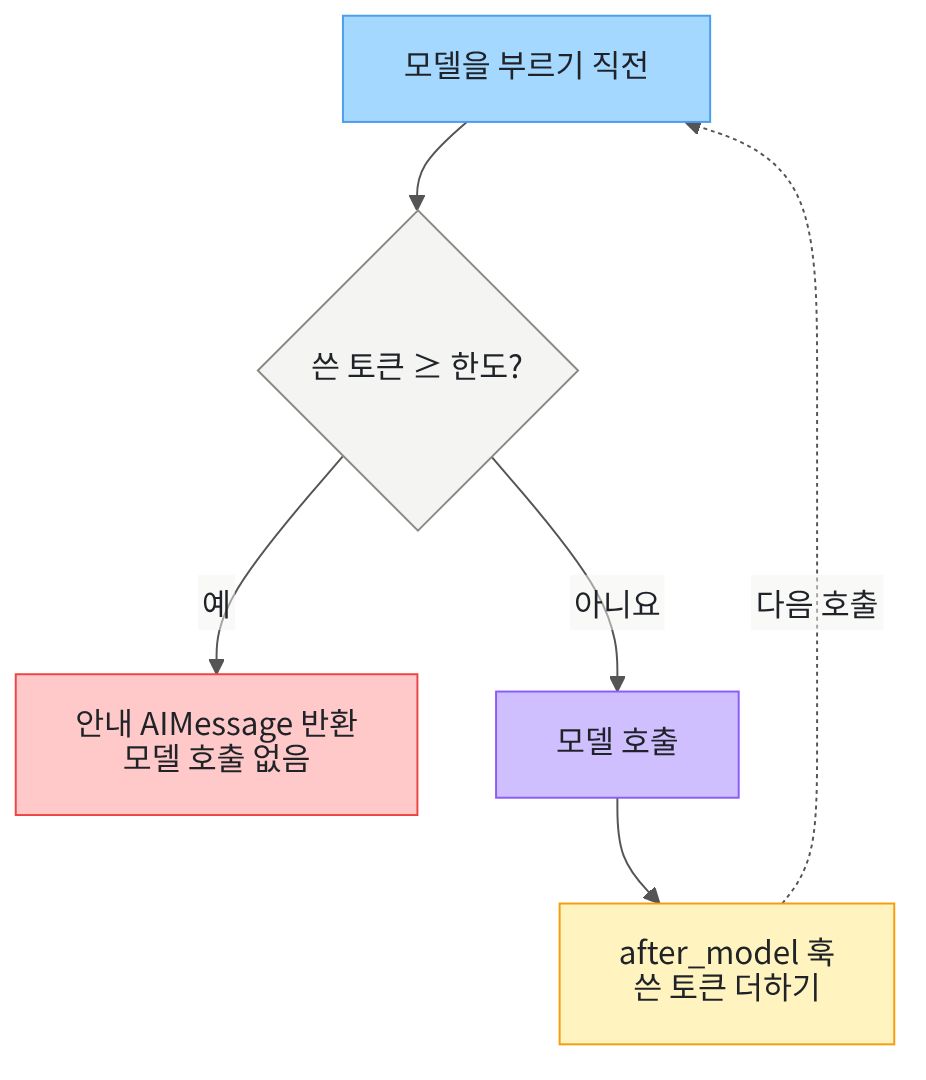

모델을 부르기 전에 쓴 토큰과 한도를 비교합니다. 한도에 닿았으면 모델을 부르지 않고 안내 메시지를 반환합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 훅 두 개(`after_model`, `wrap_model_call`)로 예산 미들웨어를 만듭니다.

In [2]:
# 에이전트·훅·메시지·모델을 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, ModelRequest, ModelResponse, Runtime
from langchain.agents.middleware import after_model, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 토큰 사용량 읽기

토큰(token)은 모델이 글을 나누어 읽는 단위입니다. 모델 서비스 비용은 보통 토큰 수로 계산합니다.
모델 응답의 `usage_metadata` 속성에 이번 호출에서 쓴 토큰 수가 들어 있습니다.

In [5]:
# 모델을 한 번 불러 사용한 토큰 수를 출력합니다
reply = model.invoke("파이썬을 한 문장으로 소개해 주세요.")
usage = reply.usage_metadata
print("입력 토큰(input_tokens):", usage["input_tokens"])
print("출력 토큰(output_tokens):", usage["output_tokens"])
print("합계(total_tokens):", usage["total_tokens"])

입력 토큰(input_tokens): 19
출력 토큰(output_tokens): 26
합계(total_tokens): 45


**결과 읽기** — 합계 `total_tokens`는 입력과 출력 토큰을 더한 값입니다. 숫자는 답 길이에 따라 실행마다 조금 달라집니다.

## 3. Before — 예산 검사 없이 두 번 부르기

예산 검사가 없는 에이전트에 질문 두 개를 차례로 보냅니다.

In [6]:
# Before: 예산 검사 없이 질문 두 개를 차례로 보냅니다
plain_agent = create_agent(model, tools=[])
first = plain_agent.invoke({"messages": [{"role": "user", "content": "파이썬을 한 문장으로 소개해 주세요."}]})
second = plain_agent.invoke({"messages": [{"role": "user", "content": "LangChain을 한 문장으로 소개해 주세요."}]})
print("첫 답:", first["messages"][-1].text)
print("둘째 답:", second["messages"][-1].text)

첫 답: 파이썬은 배우기 쉽고 다양한 분야에 활용되는 대표적인 프로그래밍 언어입니다.
둘째 답: LangChain은 **대규모 언어 모델(LLM)을 활용한 애플리케이션을 쉽게 만들고 연결할 수 있게 해주는 개발 프레임워크**입니다.


**결과 읽기** — 두 질문 모두 모델이 답했습니다. 출력의 `첫 답:` 줄과 `둘째 답:` 줄에 모두 모델의 문장이 있습니다.
답 문장은 실행할 때마다 달라질 수 있습니다.

In [7]:
# 두 호출에서 쓴 토큰을 더합니다
first_tokens = first["messages"][-1].usage_metadata["total_tokens"]
second_tokens = second["messages"][-1].usage_metadata["total_tokens"]
print("두 호출 토큰 합계:", first_tokens + second_tokens)
print("둘째 답을 만든 메시지 종류:", second["messages"][-1].type)

두 호출 토큰 합계: 104
둘째 답을 만든 메시지 종류: ai


**결과 읽기** — 둘째 답을 만든 메시지 종류가 `ai`입니다. 사용량이 아무리 늘어도 막는 장치가 없습니다.

## 4. After — 토큰 예산 미들웨어 만들기

예산 정보를 딕셔너리 하나에 담습니다. 키 `limit_tokens`는 한도, 키 `used_tokens`는 지금까지 쓴 양입니다.
실습에서는 차단을 바로 보기 위해 한도를 1토큰으로 둡니다. 첫 호출은 사용량 0에서 시작하므로 허용됩니다.

In [8]:
# 토큰 예산을 담을 딕셔너리를 만듭니다
budget = {"limit_tokens": 1, "used_tokens": 0}
print("예산:", budget)

예산: {'limit_tokens': 1, 'used_tokens': 0}


**결과 읽기** — 한도 `1`, 사용량 `0`으로 시작합니다.

첫 번째 훅은 모델 응답을 받은 직후 실행됩니다. 방금 받은 메시지의 토큰 수를 사용량에 더합니다.
`state["messages"][-1]` 값은 대화 기록의 마지막 메시지, 즉 방금 받은 응답입니다.
모델을 부르지 않고 만든 응답에는 사용량(`usage_metadata`)이 없습니다. 이때는 더하지 않고 끝냅니다.

In [9]:
# 모델 응답을 받은 직후 사용한 토큰 수를 예산에 더하는 훅
@after_model
def record_usage(state: AgentState, runtime: Runtime) -> None:
    last_message = state["messages"][-1]
    if last_message.usage_metadata is None:
        return None
    used = last_message.usage_metadata["total_tokens"]
    budget["used_tokens"] = budget["used_tokens"] + used

출력은 없습니다.

두 번째 훅은 모델을 부르기 전에 실행되는 감싸기형 훅입니다. 사용량이 한도에 닿았으면 `handler(request)`를 부르지 않습니다.
대신 안내 문장을 담은 `AIMessage`를 반환합니다. 모델이 답한 것처럼 대화가 끝나지만, 실제 모델은 호출되지 않습니다.
반환 타입에 적은 `ModelResponse | AIMessage`는 모델 응답이거나 직접 만든 AIMessage라는 뜻입니다.

In [10]:
# 모델을 부르기 전에 예산이 남았는지 검사하는 훅
@wrap_model_call
def check_budget(request: ModelRequest, handler: Callable) -> ModelResponse | AIMessage:
    if budget["used_tokens"] >= budget["limit_tokens"]:
        return AIMessage("토큰 예산을 모두 써서 모델을 부르지 않았습니다.")
    return handler(request)

출력은 없습니다. 두 훅을 등록하고 Before와 같은 질문 두 개를 보냅니다.

In [11]:
# After: 예산 미들웨어를 등록하고 같은 질문 두 개를 보냅니다
budget_agent = create_agent(model, tools=[], middleware=[check_budget, record_usage])
first = budget_agent.invoke({"messages": [{"role": "user", "content": "파이썬을 한 문장으로 소개해 주세요."}]})
second = budget_agent.invoke({"messages": [{"role": "user", "content": "LangChain을 한 문장으로 소개해 주세요."}]})
print("첫 답:", first["messages"][-1].text)
print("둘째 답:", second["messages"][-1].text)

첫 답: 파이썬은 배우기 쉽고 다양한 분야에 활용되는 범용 프로그래밍 언어입니다.
둘째 답: 토큰 예산을 모두 써서 모델을 부르지 않았습니다.


**결과 읽기** — 첫 답은 모델이 만들었고, 문장은 실행마다 달라질 수 있습니다. 둘째 답은 `토큰 예산을 모두 써서 모델을 부르지 않았습니다.`입니다.

In [12]:
# 두 번째 질문에서 모델이 호출되지 않았는지 확인합니다
second_message = second["messages"][-1]
print("사용한 토큰:", budget["used_tokens"])
print("둘째 답에 토큰 사용량이 있나:", second_message.usage_metadata is not None)
assert second_message.text == "토큰 예산을 모두 써서 모델을 부르지 않았습니다."

사용한 토큰: 45
둘째 답에 토큰 사용량이 있나: False


**결과 읽기** — 둘째 답에 토큰 사용량이 있는지 확인한 결과가 `False`입니다. 실제 모델 응답에는 사용량이 붙으므로, 모델이 호출되지 않았다는 뜻입니다.
사용한 토큰은 첫 호출에서 쓴 양만 들어 있습니다.

## 5. 값 하나 바꿔 보기 — 한도 늘리기

한도를 1,000토큰으로 늘리고 사용량을 0으로 바꿉니다. 실행 전에 예상해 봅니다. 두 질문 모두 답할 것입니다.

In [13]:
# 한도를 1,000토큰으로 늘리고 같은 질문 두 개를 다시 보냅니다
budget["limit_tokens"] = 1000
budget["used_tokens"] = 0
first = budget_agent.invoke({"messages": [{"role": "user", "content": "파이썬을 한 문장으로 소개해 주세요."}]})
second = budget_agent.invoke({"messages": [{"role": "user", "content": "LangChain을 한 문장으로 소개해 주세요."}]})
print("둘째 답을 만든 메시지에 사용량이 있나:", second["messages"][-1].usage_metadata is not None)
print("사용한 토큰:", budget["used_tokens"])

둘째 답을 만든 메시지에 사용량이 있나: True
사용한 토큰: 106


**결과 읽기** — 이번에는 `True`입니다. 한도가 넉넉하므로 두 번째 호출도 실제 모델이 답했습니다.

## 정리

- `after_model` 훅으로 호출마다 쓴 토큰을 더하고, `wrap_model_call` 훅으로 호출 전에 한도를 검사했습니다.
- 감싸기형 훅이 `handler(request)`를 부르지 않으면 모델이 호출되지 않습니다.
- 이 예산은 노트북 안의 딕셔너리에만 저장됩니다. 사용자별 하루 한도처럼 오래 유지할 값은 데이터베이스에 저장해야 합니다.